# Trajectories, level diagrams and adiabatic events with SpynDynamica

Tools of [SpynDynamica](spyndynamica.ipynb), the Python port in progress of
[SpinDynamica](https://www.spindynamica.soton.ac.uk), that look at a spin system along a coordinate: the
state during a sequence as a function of time, the limits that unitary evolution sets on a transfer, the
energy levels along a parameter of the Hamiltonian, and events that the system follows adiabatically. The
engine they build on is described in [Simulations with SpynDynamica](spyndynamica-simulations.ipynb), and the
SpinDynamica names are listed in [Coming from SpinDynamica](coming-from-spindynamica.ipynb).

SpinDynamica is the work of Malcolm H. Levitt and co-authors. Work that uses SpynDynamica should cite
C. Bengs, M. H. Levitt, *SpinDynamica: Symbolic and numerical magnetic resonance in a Mathematica environment*, Magn. Reson. Chem. (2017), doi:10.1002/mrc.4642.

*Generated from [`docs/spyndynamica-adiabatic.md`](../spyndynamica-adiabatic.md) by `docs/build_notebooks.py`; edit the Markdown guide, not this notebook.*

Run the cells in order: later cells use names defined by earlier ones. The saved outputs come from running the notebook top to bottom; plotting cells need Plotly (`pip install -e ".[docs]"`).

## Contents

1. [Trajectories as functions of time](#Trajectories-as-functions-of-time)
2. [Bounds on a transformation](#Bounds-on-a-transformation)
3. [Energy levels along a parameter](#Energy-levels-along-a-parameter)
4. [Adiabatic events](#Adiabatic-events)

## Trajectories as functions of time

`trajectory` samples the amplitudes of operators on a fixed grid. `trajectory_function` returns a function
instead, SpinDynamica's `TrajectoryFunction`: it gives the amplitude at any time of the sequence, for one time
or for an array of them. The value is exact, not interpolated: the state at the start of the event that
contains the time is propagated to it.

In [1]:
import numpy as np
import sympy as sp

from spyndynamica import Pulse, SpinSystem, operator_trajectory_function, trajectory_function

s = SpinSystem(2)
I = s.I
coupled = 2 * sp.pi * 10 * I(1, "z") - 2 * sp.pi * 4 * I(2, "z") + 2 * sp.pi * 7 * s.dot(1, 2)
echo = [Pulse(sp.pi / 2, "y"), (coupled, 0.1), Pulse(sp.pi, "x"), (coupled, 0.15)]

x1 = trajectory_function(I(1, "z"), I(1, "x"), echo)
print(x1.range)
print(round(x1(0.013).real, 4))
print(x1([0.05, 0.1, 0.17]).real.round(4))

(0.0, 0.25)
0.6228
[-0.4143 -0.4526  0.4089]


`function.range` is the time span of the events. At the time of an instantaneous event, a pulse, the value is
the one after it. With a list of operators the function returns one value per operator.
`operator_trajectory_function` gives the density matrix itself, SpinDynamica's `OperatorTrajectoryFunction`
(`NPropagate` with `Continuous -> True`):

In [2]:
state = operator_trajectory_function(I(1, "z"), echo)
print(state(0.17).shape, np.allclose(state(0.25), state(state.range[1])))

(4, 4) True


Both take `background`, `values` and `order` like `propagate`.

## Bounds on a transformation

Unitary evolution keeps the eigenvalues of the density operator, which limits how much of one operator can be
turned into another. `amplitude_bounds(rho, target)` returns the smallest and the largest amplitude
`(target|U ρ U†)/(target|target)` that any unitary transformation can reach, SpinDynamica's
`TransformationAmplitudeBounds`:

In [3]:
from spyndynamica import amplitude_bounds

print(amplitude_bounds(I(1, "z"), I(2, "z")))
print(amplitude_bounds(I(1, "z"), s.dot(1, 2)).round(4))
print(amplitude_bounds(I(None, "z"), [I(1, "z"), 2 * I(1, "z") @ I(2, "z"), s.dot(1, 2)]).round(4))

[-1.  1.]
[-0.6667  0.6667]
[[-1.      1.    ]
 [-1.      1.    ]
 [-1.3333  1.3333]]


The magnetisation of one spin can be moved to the other completely. Into singlet order `I1·I2` it goes with
an amplitude of at most 2/3, and the total magnetisation of both spins gives twice that. The bounds
are sums of products of the sorted eigenvalues of the two operators, which must be Hermitian. They say what is
possible, not which sequence does it; `maximize_amplitude` searches for one.

## Energy levels along a parameter

`correlated_eigensystems(H, parameter, values)` diagonalises a Hamiltonian at every value of a parameter and
follows each eigenstate from one value to the next, SpinDynamica's `CorrelatedEigensystems`. The result holds
the `values`, the `eigenvalues` (one row per value, one column per state) and the `eigenvectors`.

The example is a pair of coupled spins whose difference of Larmor frequencies `Δ` goes through zero, as in a
field sweep through a level anticrossing:

In [4]:
from spyndynamica import correlated_eigensystems

delta = sp.Symbol("Delta", real=True)
pair = delta * (I(1, "z") - I(2, "z")) / 2 + 2 * sp.pi * 10 * s.dot(1, 2)
offsets = 2 * np.pi * np.linspace(-100, 100, 81)
levels = correlated_eigensystems(pair, delta, offsets)
print(levels.eigenvalues.shape, levels.eigenvectors.shape)
print((levels.eigenvalues[[0, 40, 80]] / (2 * np.pi)).round(2))

(81, 4) (81, 4, 4)
[[-52.75   2.5    2.5   47.75]
 [ -7.5    2.5    2.5    2.5 ]
 [-52.75   2.5    2.5   47.75]]


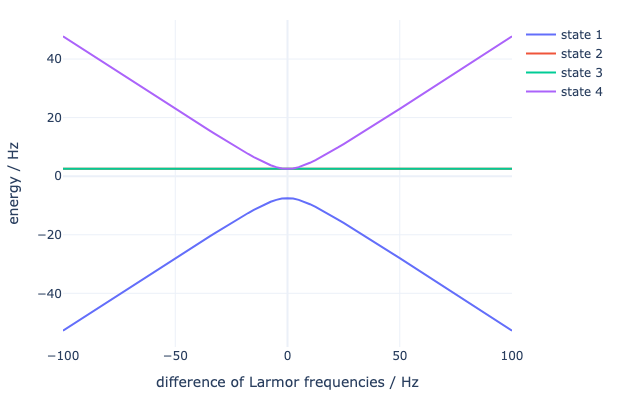

In [5]:
import plotly.graph_objects as go

# a plotly line plot of the four energy levels against the frequency difference
figure = go.Figure()
for state in range(4):
    figure.add_scatter(x=offsets / (2 * np.pi), y=levels.eigenvalues[:, state] / (2 * np.pi), name=f"state {state + 1}")
figure.update_xaxes(title="difference of Larmor frequencies / Hz")
figure.update_yaxes(title="energy / Hz")
figure.update_layout(width=620, height=400, margin=dict(l=60, r=20, t=20, b=50), template="plotly_white")
figure

Two levels, the triplet states `|αα⟩` and `|ββ⟩`, do not depend on `Δ` and lie on top of each other. The other
two approach to within the coupling, 10 Hz, and turn away: each is one product state far to the left, the
singlet or the central triplet state in the middle, and the other product state far to the right.

A state continues into the state of the next value that it overlaps with most and whose eigenvalue is
closest, so lines that cross keep their states and lines that avoid each other follow the eigenvalues. At the
first value the states are in ascending order of the eigenvalues. The generator may also be a superoperator
(a Liouvillian, with complex eigenvalues), a matrix of expressions in the parameter, or a plain list of
numeric matrices; `background` is added to an operator or superoperator. `levels.tracks()` gives the
`(value, eigenvalue)` pairs per state, the form in which SpinDynamica lists them.

## Adiabatic events

When a Hamiltonian changes slowly on the scale of the gaps between its levels, the system stays in the
eigenstate it started in. `Adiabatic(generator, duration)` is an event that assumes this, SpinDynamica's
`PropagationMethod -> Adiabatic`: the equation of motion is not integrated, the eigenstates are followed on a
grid of `sampling` steps (100 by default), and the population of every eigenstate at the start goes to the
state it turns into. The cost is one diagonalisation per grid point, however long the event lasts.

A sweep of `Δ` through the anticrossing of the last section exchanges `|αβ⟩` and `|βα⟩`, and so the
magnetisation of the two spins:

In [6]:
from spyndynamica import Adiabatic, TimeDependent, amplitudes

time = sp.Symbol("t", real=True)
duration = 2.0
sweep = TimeDependent(pair.subs(delta, 2 * sp.pi * 100 * (1 - 2 * time / duration)), time)

targets = [I(1, "z"), I(2, "z")]
print(amplitudes(I(1, "z"), targets, [Adiabatic(sweep, duration)]).real.round(4))
print(amplitudes(I(1, "z"), targets, [(sweep, duration)]).real.round(4))

[0.005 0.995]
[1.000e-04 9.999e-01]


The second line integrates the equation of motion and agrees within half a percent. A sweep a hundred
times faster no longer is adiabatic, and the event then gives the wrong answer without a warning:

In [7]:
quick = TimeDependent(pair.subs(delta, 2 * sp.pi * 100 * (1 - 2 * time / 0.02)), time)
print(amplitudes(I(1, "z"), targets, [Adiabatic(quick, 0.02)]).real.round(4))
print(amplitudes(I(1, "z"), targets, [(quick, 0.02)]).real.round(4))

[0.005 0.995]
[0.8555 0.1445]


By default the coherences between eigenstates are dropped, also those of the initial state
(`delete_coherences=True`, as in SpinDynamica). With `delete_coherences=False` they are kept with their
phase, the integral of the difference of the two eigenvalues plus the geometric phase, and the event is
unitary. `sampling` is a number of steps or a list of times from the start of the event. An adiabatic event
works in trajectories like any other event:

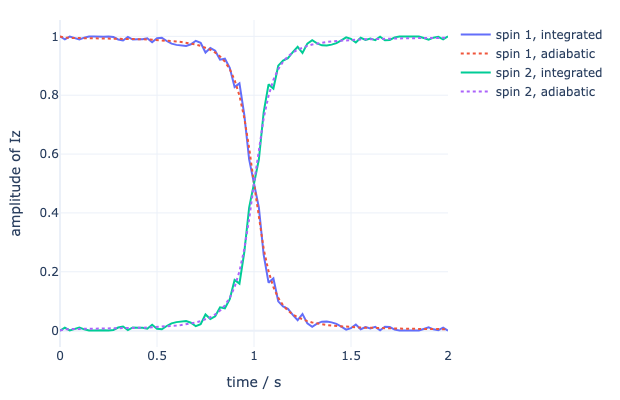

In [8]:
followed = trajectory_function(I(1, "z"), targets, [Adiabatic(sweep, duration)])
integrated = trajectory_function(I(1, "z"), targets, [(sweep, duration)])
moments = np.linspace(0, duration, 81)

# a plotly line plot: the two magnetisations during the sweep, adiabatic event against integration
figure = go.Figure()
for row, name in enumerate(("spin 1", "spin 2")):
    figure.add_scatter(x=moments, y=integrated(moments)[row].real, name=f"{name}, integrated")
    figure.add_scatter(x=moments, y=followed(moments)[row].real, name=f"{name}, adiabatic", line=dict(dash="dot"))
figure.update_xaxes(title="time / s")
figure.update_yaxes(title="amplitude of Iz")
figure.update_layout(width=620, height=400, margin=dict(l=60, r=20, t=20, b=50), template="plotly_white")
figure

Relaxation during an adiabatic event is not available.